<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/exercise/Threefold_split_cs%26hyperparameter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
from sklearn.datasets import make_classification
# make_classification
X, y = make_classification()
X.shape

(100, 20)

In [13]:
# @title **1. Generate Data**
X, y = make_classification(n_samples=1000,
                           n_features= 10,
                           n_informative= 4,
                           random_state=42)

In [5]:
! pip install mglearn

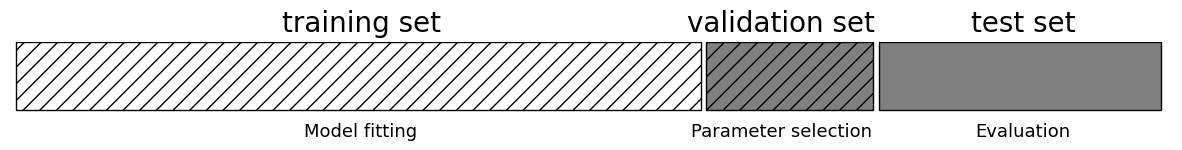

In [4]:
import mglearn
mglearn.plots.plot_threefold_split()

In [24]:
# @title **방법 A: Three-Way Split (70:15:15)**

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import tqdm

# 1. 데이터 분할

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# 2. 하이퍼파라미터 후보
params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10]
}

# 3. Validation으로 튜닝
best_score = 0

for n in tqdm.tqdm(params['n_estimators']):
    for d in params['max_depth']:
        print(f"n_estimators: {n}, max_depth: {d}")
        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=d,
            random_state=42
        )

        model.fit(X_train, y_train)
        score = accuracy_score(y_val, model.predict(X_val))

        if score > best_score:
            best_score = score
            best_params = {'n_estimators': n, 'max_depth': d}

# 4. 최적 파라미터로 Train + Validation 재학습
model = RandomForestClassifier(**best_params, random_state=42)
model.fit(
    __import__('numpy').concatenate([X_train, X_val]),
    __import__('numpy').concatenate([y_train, y_val])
)

# 5. Test 평가
print('\n\nTest 평가')
print("*"*100)
print("Best Parameters:", best_params)
print("Validation Accuracy:", best_score)
print("Test Accuracy:", accuracy_score(y_test, model.predict(X_test)))

  0%|          | 0/3 [00:00<?, ?it/s]

n_estimators: 50, max_depth: 3
n_estimators: 50, max_depth: 5
n_estimators: 50, max_depth: 10


 33%|███▎      | 1/3 [00:00<00:01,  1.40it/s]

n_estimators: 100, max_depth: 3
n_estimators: 100, max_depth: 5
n_estimators: 100, max_depth: 10


 67%|██████▋   | 2/3 [00:02<00:01,  1.19s/it]

n_estimators: 200, max_depth: 3
n_estimators: 200, max_depth: 5
n_estimators: 200, max_depth: 10


100%|██████████| 3/3 [00:05<00:00,  1.88s/it]




Test 평가
****************************************************************************************************
Best Parameters: {'n_estimators': 200, 'max_depth': 10}
Validation Accuracy: 0.9066666666666666
Test Accuracy: 0.92


### simple code

In [31]:
from itertools import product
list(product([50, 100, 200], [3, 5, 10]))

[(50, 3),
 (50, 5),
 (50, 10),
 (100, 3),
 (100, 5),
 (100, 10),
 (200, 3),
 (200, 5),
 (200, 10)]

In [30]:
import numpy as np
from itertools import product

# 1. 데이터 분할 (70 / 15 / 15)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)

# 2. Validation으로 튜닝
def val_score(n, d):
    m = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=42).fit(X_train, y_train)
    return accuracy_score(y_val, m.predict(X_val))

grid = product([50, 100, 200], [3, 5, 10])
(best_n, best_d), best_score = max(((p, val_score(*p)) for p in grid), key=lambda t: t[1])

# 3. Train + Validation으로 재학습 후 Test 평가
model = RandomForestClassifier(n_estimators=best_n, max_depth=best_d, random_state=42)
model.fit(np.concatenate([X_train, X_val]), np.concatenate([y_train, y_val]))

print("Best Parameters:", {"n_estimators": best_n, "max_depth": best_d})
print("Validation Accuracy:", best_score)
print("Test Accuracy:", accuracy_score(y_test, model.predict(X_test)))

Best Parameters: {'n_estimators': 200, 'max_depth': 10}
Validation Accuracy: 0.9066666666666666
Test Accuracy: 0.92
grid: []


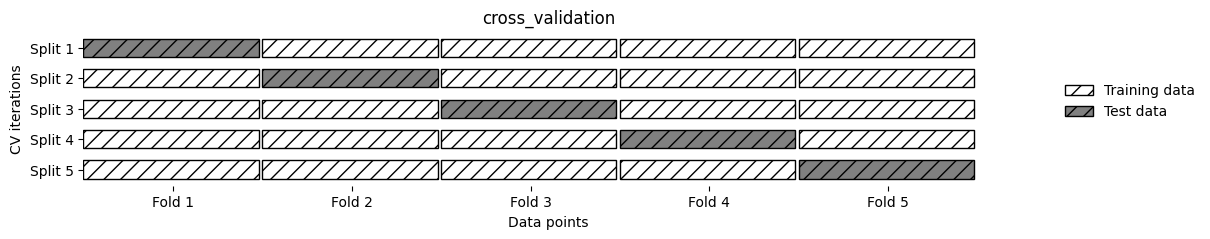

In [32]:
mglearn.plots.plot_cross_validation()

In [34]:
# @title **방법 B: Train/Test + 5-Fold Cross Validation**

from sklearn.model_selection import train_test_split, GridSearchCV

# 3. 5-Fold Cross Validation으로 튜닝
grid = GridSearchCV(
    model,
    params,
    cv=5,
    scoring='accuracy',
    verbose=1,
    n_jobs=-1
)

grid.fit(X_train, y_train)

# 4. 최적 모델로 Test 평가
best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)
print("CV Accuracy:", grid.best_score_)
print("Test Accuracy:", accuracy_score(y_test, best_model.predict(X_test)))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best Parameters: {'max_depth': 10, 'n_estimators': 200}
CV Accuracy: 0.9099999999999999
Test Accuracy: 0.915
